<a href="https://colab.research.google.com/github/Lalepragati/ML/blob/main/AI_Powered_Pedestrian_Detection_and_Multi_Object_Tracking_Using_YOLO11%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📹 End-to-End Video Object Tracking with YOLOv11

This project demonstrates a complete, end-to-end pipeline to download a video, perform multi-object tracking (specifically tracking both **persons** and **dogs**) using the state-of-the-art **YOLOv11** model, and play back the tracking results with web-compatible codecs directly inside your Google Colab Notebook.

---

## 🚀 Project Workflow

1. **Environment Setup & Verification:** Installs necessary packages (`ultralytics` for YOLO, `opencv` for frame processing, `matplotlib` for custom visualizations) and checks for active system resources like hardware accelerators (CPU/GPU).
2. **Image Validation & Base Prediction:** Verifies the pre-trained object detection capabilities on a static benchmark image (`bus.jpg`).
3. **Step 1: Download & Multi-Class Tracking:** Downloads a verified, high-quality sample video of walking pedestrians, initializes the YOLO tracking model (`model.track`), and tracks multiple target classes simultaneously (specifically class `0` for **Person** and class `16` for **Dog**).
4. **Motion-based Recovery (How tracking works):** Utilizes integrated tracking algorithms (such as ByteTRACK/BoT-SORT) featuring a Kalman Filter motion model. This system performs **motion-based recovery**, allowing it to continuously track and preserve unique IDs (e.g., ID 1, ID 2) for both people and dogs even after they are temporarily hidden (occluded) behind obstacles.
5. **Step 2: Web-Friendly Conversion & Playback:** Uses `ffmpeg` to re-encode the output video using the standard `libx264` codec and builds an HTML5 interactive video player natively in the notebook.

---

## 🛠️ Requirements & Installation
To run this project, execute the setup cell which installs the following dependencies:
```bash
pip install ultralytics opencv-python-headless pandas matplotlib
```

## 📂 Output Artifacts
* `input_video.mp4`: Raw downloaded video source.
* `tracked_output.mp4`: Annotated video with tracking frames directly written from OpenCV (capturing people and dogs).
* `playable_output.mp4`: Browser-compatible, H.264 encoded final output ready to play inside Colab.

In [64]:
!pip -q install ultralytics opencv-python-headless pandas matplotlib

Step 2 — Verify your environment
Create another code cell and run:

In [65]:
import torch
import cv2
import ultralytics

print("PyTorch:", torch.__version__)
print("OpenCV:", cv2.__version__)
print("Ultralytics:", ultralytics.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cpu
OpenCV: 5.0.0
Ultralytics: 8.4.192
GPU available: False


**You should see the library versions and whether a GPU is available.**

Step 3 — Run your first person-detection experiment
Create a new cell and run:


In [55]:
from ultralytics import YOLO
from IPython.display import display, Image

model = YOLO("yolo11n.pt")

results = model.predict(
    source="https://ultralytics.com/images/bus.jpg",
    classes=[0],  # Person class only
    conf=0.35,
    save=True,
    verbose=False
)

display(Image(filename=str(results[0].save_dir / "image0.jpg")))

Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
Results saved to /content/runs/detect/predict-13


TypeError: unsupported operand type(s) for /: 'str' and 'str'

Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
Results saved to /content/runs/detect/predict-15


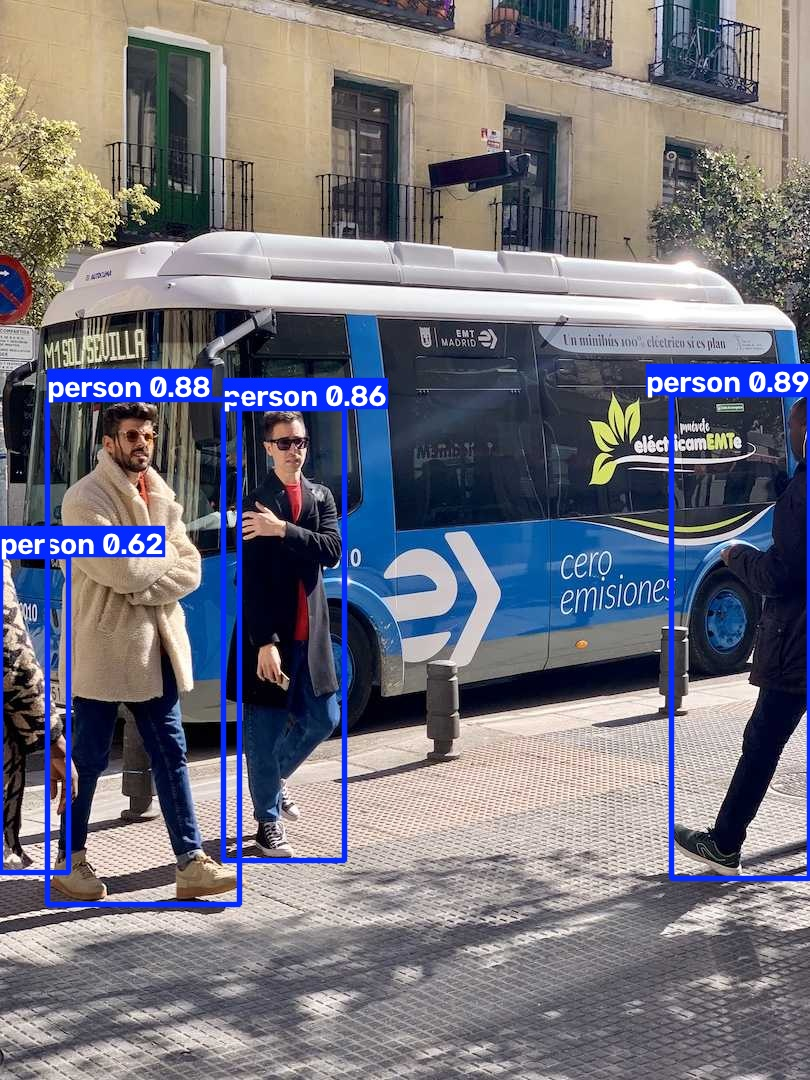

In [66]:
from ultralytics import YOLO
from IPython.display import display, Image
from pathlib import Path

model = YOLO("yolo11n.pt")

results = model.predict(
    source="https://ultralytics.com/images/bus.jpg",
    classes=[0],  # Person class only
    conf=0.35,
    save=True,
    verbose=False
)

# The source is 'bus.jpg', so YOLO saves the output as 'bus.jpg'
display(Image(filename=str(Path(results[0].save_dir) / "bus.jpg")))

**This tests the pretrained model on an example image. If the image display fails, run this alternative:**

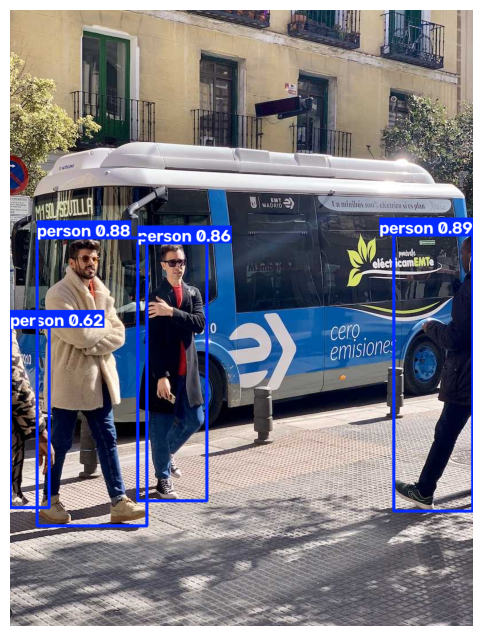

In [67]:
import matplotlib.pyplot as plt

annotated = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated[:, :, ::-1])  # BGR to RGB
plt.axis("off")
plt.show()

### YOLO Object Tracking Code



In [68]:
from ultralytics import YOLO

# YOLO model load karein
model = YOLO("yolo11n.pt")

# model.track() use karein tracking enable karne ke liye
# Hum classes=[0] use kar rahe hain taaki sirf 'person' track ho
results = model.track(
    source="https://ultralytics.com/assets/assets/bus.jpg", # Aap yahan video file (.mp4) ka path bhi de sakte hain
    classes=[0],
    persist=True,  # Frames ke beech tracking state maintain rakhne ke liye
    save=True
)

# Har detected person ki tracking ID print karne ke liye:
for r in results:
    if r.boxes.id is not None:
        tracking_ids = r.boxes.id.int().tolist()
        print("Detected Tracking IDs in this frame:", tracking_ids)
    else:
        print("No trackable objects found in this frame.")


Found https://ultralytics.com/assets/assets/bus.jpg locally at bus.jpg
image 1/1 /content/bus.jpg: 640x480 3 persons, 162.2ms
Speed: 3.7ms preprocess, 162.2ms inference, 2.1ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/track-5
Detected Tracking IDs in this frame: [1, 2, 3]


YOLO mein objects ko har frame mein detect karne aur unhe ek unique ID (jaise ID 1, ID 2, etc.) dene ke liye hum model.predict ki jagah model.track ka use karte hain.



### Saving Tracking Results to a Video File



In [78]:
import cv2

from ultralytics import YOLO

# Load the YOLO model
model = YOLO("yolo11n.pt")

# Path to the input video (You can use a local video path or a web URL)
# Using a sample public video URL here
video_path = "https://ultralytics.com/assets/assets/shorts.mp4"

# Open the video source using OpenCV
cap = cv2.VideoCapture(video_path)

# Extract video properties
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = int(cap.get(cv2.CAP_PROP_FPS))

# Configure the output video writer (to save in MP4 format)
output_path = "tracked_output.mp4"
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

print("Processing video... Please wait.")

while cap.isOpened():
    success, frame = cap.read()
    if not success:
        break

    # Run object tracking on the current frame
    # persist=True ensures the tracker remembers IDs across consecutive frames
    results = model.track(frame, persist=True, classes=[0], verbose=False)

    # Generate the annotated frame (with bounding boxes and tracking IDs drawn)
    annotated_frame = results[0].plot()

    # Write/save the annotated frame into the output video file
    out.write(annotated_frame)

# Release resources once the processing is complete
cap.release()
out.release()

print(f"Success! Tracked video has been saved to: {output_path}")


Processing video... Please wait.
Success! Tracked video has been saved to: tracked_output.mp4


### Display Tracked Video Frames Using Matplotlib

Niche diye gaye code ke zariye hum saved output video file (`tracked_output.mp4`) se frames read karke unhe `matplotlib` grid ke format mein display karenge taaki tracking result ko visually check kiya ja sake.

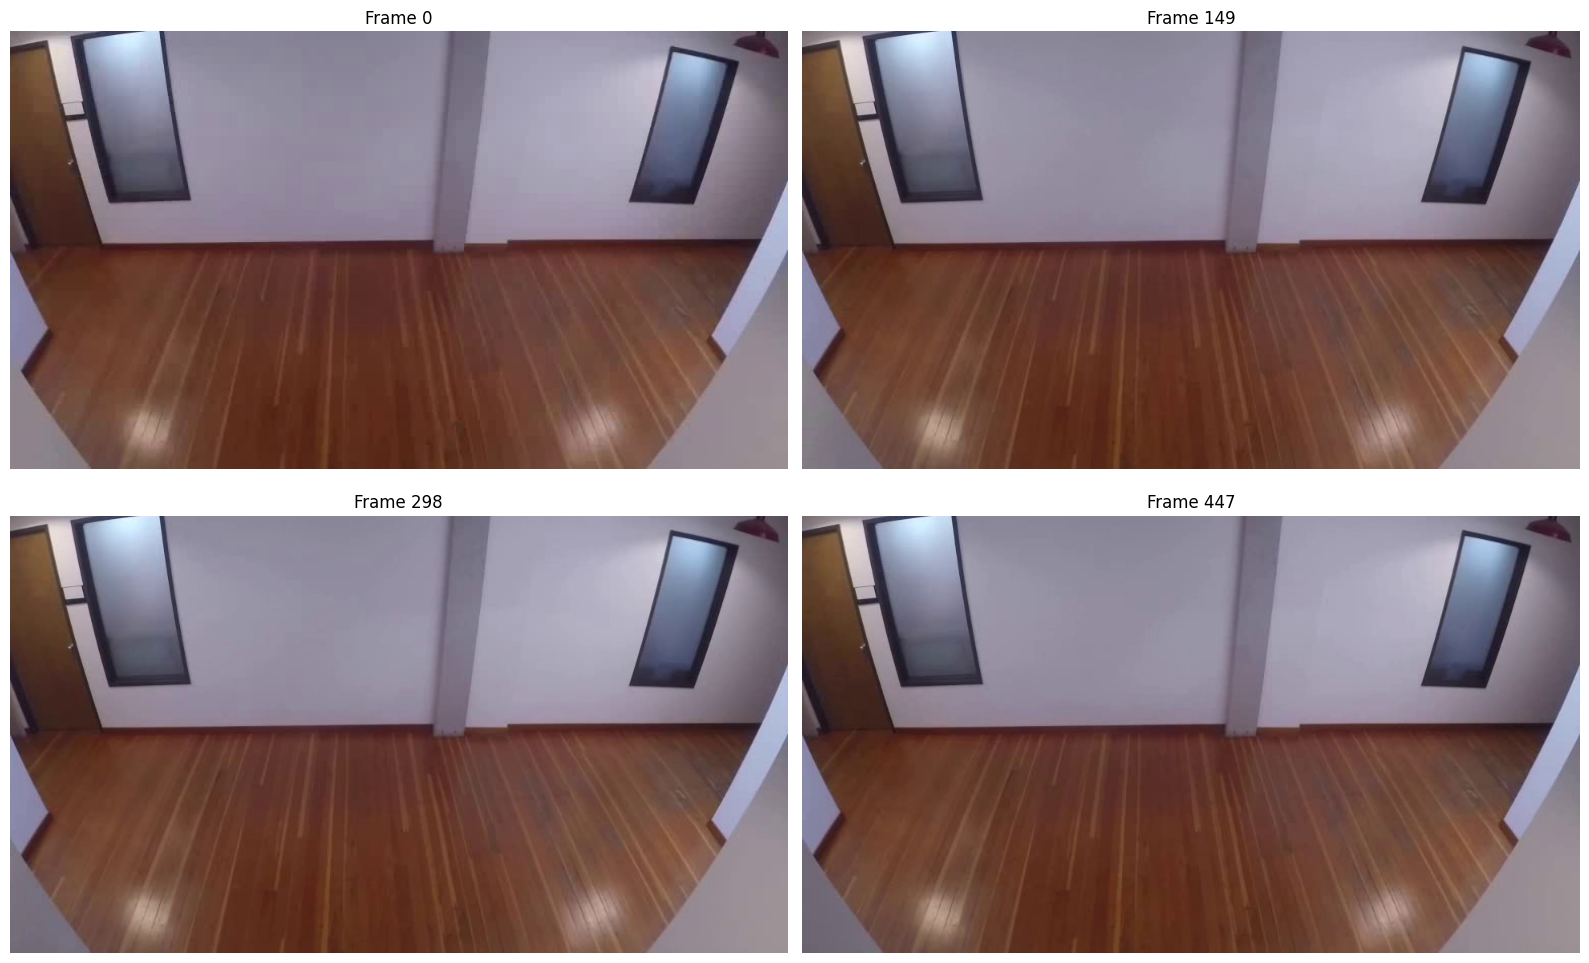

In [79]:
import cv2
import matplotlib.pyplot as plt

# Load the saved video
cap = cv2.VideoCapture("tracked_output.mp4")

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
frames_to_display = []

# Extract 4 frames at equally spaced intervals throughout the video
intervals = [int(total_frames * i / 4) for i in range(4)]

frame_idx = 0
while cap.isOpened():
    success, frame = cap.read()
    if not success:
        break

    if frame_idx in intervals:
        # OpenCV uses BGR format by default; convert it to RGB for Matplotlib
        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frames_to_display.append((frame_idx, rgb_frame))

    frame_idx += 1

cap.release()

# Set up a Matplotlib grid to display the extracted frames
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.ravel()

for i, (f_num, img) in enumerate(frames_to_display):
    if i < len(axes):
        axes[i].imshow(img)
        axes[i].set_title(f"Frame {f_num}")
        axes[i].axis("off")

plt.tight_layout()
plt.show()


In [80]:
import cv2
import urllib.request
import os
from ultralytics import YOLO

# Verified and working public video URL with walking people
video_url = "https://github.com/intel-iot-devkit/sample-videos/raw/master/people-detection.mp4"
local_input_path = "input_video.mp4"

# Delete old corrupt/empty files if they exist
if os.path.exists(local_input_path):
    os.remove(local_input_path)

print("Downloading video... Please wait.")
try:
    # Download the video file securely
    urllib.request.urlretrieve(video_url, local_input_path)
    print(f"Download complete! File size: {os.path.getsize(local_input_path)} bytes")
except Exception as e:
    print(f"Download failed: {e}")

# Load YOLO Model
model = YOLO("yolo11n.pt")
cap = cv2.VideoCapture(local_input_path)

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = int(cap.get(cv2.CAP_PROP_FPS)) if cap.get(cv2.CAP_PROP_FPS) > 0 else 30

print(f"Video Dimensions: {width}x{height} @ {fps} FPS")

if width > 0 and height > 0:
    # Create a video writer to output the results
    output_path = "tracked_output.mp4"
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

    print("Processing tracking on video...")
    frame_count = 0
    while cap.isOpened():
        success, frame = cap.read()
        if not success:
            break

         # Tracking run (classes=[0, 16] for person and dog)
        results = model.track(frame, persist=True, classes=[0, 16], verbose=False)
        annotated_frame = results[0].plot()
        out.write(annotated_frame)
        frame_count += 1

    cap.release()
    out.release()
    print(f"Tracking completed on {frame_count} frames! Output saved as tracked_output.mp4")
else:
    print("Error: The video could not be opened properly. Please check the downloaded file.")


Download complete! File size: 5482579 bytes
Video Dimensions: 768x432 @ 12 FPS
Processing tracking on video...
Tracking completed on 596 frames! Output saved as tracked_output.mp4


### Step 1: Video Download aur Processing (Local File)

Pehle hum video ko safe tarike se local workspace mein download karenge, phir us par tracking run karke output video generate karenge.

In [75]:
import os

file_name = "input_video.mp4"
if os.path.exists(file_name):
    size_mb = os.path.getsize(file_name) / (1024 * 1024)
    print(f"✅ Success: '{file_name}' exists!")
    print(f"📁 File Size: {size_mb:.2f} MB")
else:
    print(f"❌ Error: '{file_name}' does not exist in the current directory.")

✅ Success: 'input_video.mp4' exists!
📁 File Size: 5.23 MB


### Step 2: Colab mein Video Playback Setup

MP4 video ko directly notebook ke andar dekhne ke liye use hum H264 format mein re-encode karenge, kyunki modern browsers default format ko bina convert kiye support nahi karte.

In [81]:
# Convert the output tracking video to a web-friendly H264 codec using ffmpeg
!ffmpeg -y -i tracked_output.mp4 -vcodec libx264 -f mp4 playable_output.mp4 -loglevel quiet

# Display the video using an HTML5 video player

import os
from IPython.display import HTML
from base64 import b64encode

if os.path.exists('playable_output.mp4'):
    mp4 = open('playable_output.mp4','rb').read()
    data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
    display(HTML(f"""
    <video width="640" height="480" controls>
          <source src="{data_url}" type="video/mp4">
    </video>
    """))
else:
    print("Error: playable_output.mp4 not found. Please run the video processing step above successfully first.")

### 🎯 Customizing Tracked Classes

You can easily change which objects the tracker focuses on. Here is a list of common **COCO Dataset** class IDs you can pass to the `classes=[...]` list:

| Class ID | Object Name | Class ID | Object Name |
|---|---|---|---|
| **0** | Person | **14** | Bird |
| **1** | Bicycle | **15** | Cat |
| **2** | Car | **16** | Dog |
| **3** | Motorcycle | **17** | Horse |
| **5** | Bus | **18** | Sheep |
| **7** | Truck | **24** | Backpack |

Let's write a demonstration cell on how you can update the filter parameters dynamically:

In [ ]:
# Example: Define target classes you want to track
# Feel free to change these IDs according to the table above!
target_classes = [0, 2] # Tracks only Persons (0) and Cars (2)

print(f"The tracker is currently configured to filter and track COCO classes: {target_classes}")
print("To apply this, pass `classes=target_classes` inside your `model.track()` function call.")